# Modelo SVM: utilidad de las parcelas de eucalipto

**Proyecto:** clasificación multiclase de la utilidad para la conservación del suelo de parcelas de eucalipto (dataset Eucalyptus).
**Historia:** #40 · **Notebook:** `04_svm.ipynb`

Este notebook sigue la plantilla común de `docs/acuerdos.md`: carga los CSV con `comun.py`, entrena un SVM dentro de un `Pipeline`, mide con las dos validaciones cruzadas, evalúa en validación, interpreta el modelo y guarda el pipeline y las cifras.

- **Datos:** `data/train.csv` y `data/val.csv`. El conjunto de prueba no se lee: se reserva para `06_conclusiones`.
- **Regla de las parcelas sin medidas:** ADR-0001. Si faltan las seis medidas, se responde `none` sin llamar al modelo.
- **Validación:** `StratifiedKFold` de 5 folds y, aparte, `StratifiedGroupKFold` por sitio (ADR-0002).
- **Overfitting:** gap = F1 macro de train − F1 macro de validación con medidas, con signo; debe ser menor de 5 puntos.

## Apunte Elena: el cuento del modelo

Imagina que tenemos 736 árboles de eucalipto y queremos adivinar si son none, low, average, good o best. Hicimos una “máquina adivinadora” y la entrenamos.

- Separamos los árboles en tres grupos: unos para practicar (train), otros para probar lo aprendido (val) y otros guardados para el examen final (test), que no miramos.
- La máquina (SVM) mira pistas: lo vigoroso que está el árbol, si sobrevivió, su altura, su diámetro y el sitio donde se plantó.
- Regla especial: si a un árbol le faltan todas las medidas, no preguntamos a la máquina: respondemos none directamente.
- Practicamos 5 veces con trozos distintos de los datos (validación cruzada) y también por sitios, para ver si hacía trampas aprovechando que árboles del mismo sitio se parecen.
- Resultado: sacó una nota de 0,636 sobre 1 en la prueba (0,601 solo con parcelas medidas). Comprobamos que no se había “aprendido de memoria” las respuestas: no hay sobreajuste.
- Descubrimos las pistas más útiles: el vigor es la más importante, luego la supervivencia, la altura y el diámetro.
- Sus errores típicos: confunde best con good, como confundir “muy bueno” con “bueno”.
- Guardamos la máquina en una caja (`models/04_svm.joblib`) para que la app pueda usarla más tarde.

## Pasos 0, 1 y 2: problema, split y EDA (ya hechos)

| Paso | Dónde está | Resumen |
|---|---|---|
| 0. Definir el problema | `00_general.ipynb` | Predecir `Utility` en 5 clases ordenadas (`none` < `low` < `average` < `good` < `best`). Métrica principal: **F1 macro**; sobreajuste < 5 puntos. |
| 1. Datos y split | `01_eda.ipynb`, sección 10 | Split estratificado 70/15/15 con semilla 42 y CSV en `data/`. |
| 2. EDA | `01_eda.ipynb` y `docs/informe-eda.md` | El **sitio** marca mucho la clase; el **vigor** es la medida más relacionada; hay parcelas sin medidas que son todas `none`. |

Aquí empezamos en el preprocesado y el modelo.

## Paso 1 (bis): cargar los datos con `comun.py`

**Qué hacemos:** importamos la librería común y leemos `train.csv` y `val.csv`. `comun.py` concentra las reglas del equipo: semilla, orden de las clases, regla `none`, validaciones y evaluación.

**Cómo leer el resultado:** comprobamos el tamaño de cada conjunto y cuántas parcelas hay de cada clase.

In [1]:
import pandas as pd

from comun import CLASES, OBJETIVO, cargar_datos, separar_xy  # noqa: F401

train, val = cargar_datos()  # data/train.csv y data/val.csv; el test no se lee aquí

print(f"train: {train.shape[0]} filas x {train.shape[1]} columnas")
print(f"val:   {val.shape[0]} filas x {val.shape[1]} columnas")

pd.DataFrame({
    "train": train[OBJETIVO].value_counts(),
    "val": val[OBJETIVO].value_counts(),
}).reindex(CLASES)

train: 469 filas x 13 columnas
val:   110 filas x 13 columnas


,train,val
Utility,,
none,80,27
low,75,16
average,91,19
good,150,32
best,73,16


### Las parcelas sin medidas

**Qué hacemos:** contamos las parcelas a las que les faltan **todas** las medidas del árbol.

**Por qué:** según el ADR-0001, esas parcelas no pasan por el modelo: se predicen `none` por regla fija. En train deben ser 0 (ya se quitaron); en validación son 15, todas de clase `none`.

In [2]:
from comun import MEDIDAS, sin_medidas  # noqa: F401

print("Parcelas sin medidas en train:", sin_medidas(train).sum())
print("Parcelas sin medidas en val:  ", sin_medidas(val).sum())
print("Clase de las de val:", val.loc[sin_medidas(val), OBJETIVO].value_counts().to_dict())

Parcelas sin medidas en train: 0
Parcelas sin medidas en val:   15
Clase de las de val: {'none': 15}


## Paso 3: preprocesado

| Tipo de columna | Columnas | Tratamiento |
|---|---|---|
| Numéricas | `DBH`, `Ht`, `Surv`, `Vig`, `Ins_res`, `Stem_Fm`, `Crown_Fm`, `Brnch_Fm` | Imputar la mediana y **estandarizar** |
| Categóricas | `Abbrev` (sitio) | One-hot con `handle_unknown="ignore"` |

**Por qué:**
- El SVM es sensible a la escala: una variable con valores grandes pesaría más solo por su tamaño. Por eso se estandariza.
- Faltan valores en `Surv` (parcelas del sitio Cly) y en un `DBH` (el diámetro erróneo de 42 085 cm, convertido en hueco). Se imputan con la mediana.
- Se excluyen `Rep` y `PMCno` por ser identificadores y `Sp` porque tiene 25 especies, muchas con 2 o 3 parcelas; en un SVM lineal, 25 columnas one-hot tan dispersas aumentan el sobreajuste sin mejorar el F1 de la validación cruzada. El **sitio** (`Abbrev`) sí entra.

Todo el preprocesado va dentro del `Pipeline`, así se ajusta **solo con train**.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from comun import NUMERICAS

CATEGORICAS = ["Abbrev"]
VARIABLES = NUMERICAS + CATEGORICAS

X_train, y_train = separar_xy(train, VARIABLES)
X_val, y_val = separar_xy(val, VARIABLES)

print("Variables del modelo:", VARIABLES)
print("Excluidas:", [c for c in train.columns if c not in VARIABLES + [OBJETIVO]])

preprocesado = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputar", SimpleImputer(strategy="median")),
                ("escalar", StandardScaler()),
            ]),
            NUMERICAS,
        ),
        (
            "cat",
            Pipeline([
                ("imputar", SimpleImputer(strategy="most_frequent")),
                ("codificar", OneHotEncoder(handle_unknown="ignore")),
            ]),
            CATEGORICAS,
        ),
    ],
    remainder="drop",
)

Variables del modelo: ['DBH', 'Ht', 'Surv', 'Vig', 'Ins_res', 'Stem_Fm', 'Crown_Fm', 'Brnch_Fm', 'Abbrev']
Excluidas: ['Rep', 'Sp', 'PMCno']


## Paso 4: baseline (el mínimo a superar)

**Qué hacemos:** medimos un `DummyClassifier`, que no mira los datos y siempre responde la clase más frecuente (`good`), con la misma regla `none` para las parcelas sin medidas.

**Por qué:** la guía pide una referencia. Si el SVM no supera claramente al Dummy, no está aprendiendo nada útil. `baseline_dummy` de `comun.py` devuelve el F1 en CV, en toda la validación y solo con las parcelas con medidas.

In [4]:
from comun import baseline_dummy

f1_dummy = baseline_dummy(X_train, y_train, X_val, y_val)

El Dummy responde siempre «good» (y «none» a las parcelas sin medidas, por la regla).


,F1 macro,accuracy
cv,0.097,0.320
toda la validación,0.244,0.427
solo con medidas,0.101,0.337


## Paso 5: entrenamiento y validación cruzada

**Qué hacemos:** montamos el `Pipeline` con un SVM lineal y lo evaluamos con las dos validaciones cruzadas de `comun.py`:

- `StratifiedKFold` de 5 folds, el esquema común.
- `StratifiedGroupKFold` por `Abbrev`, para ver cuánto se infla la métrica cuando el modelo ve parcelas del mismo sitio en train y validación (ADR-0002).

**Cómo leer el resultado:** miramos el F1 macro medio y el **gap** (F1 train − F1 CV). Un gap grande significa que el modelo memoriza train.

Primero con un `C = 1` (poca regularización) para ver el problema.

In [5]:
from sklearn.svm import SVC

from comun import SEMILLA, f1_por_fold

modelo_base = Pipeline([
    ("preprocesado", preprocesado),
    ("svm", SVC(kernel="linear", C=1.0, random_state=SEMILLA)),
])

cv_base = f1_por_fold(modelo_base, X_train, y_train)

,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.572,0.583
2,0.675,0.517
3,0.585,0.394
4,0.560,0.671
5,0.446,0.592


StratifiedKFold: F1 macro = 0.568 ± 0.073 | gap 15.0 puntos ❌ sobreajuste grave
Por sitio:       F1 macro = 0.551 ± 0.093 | gap 13.8 puntos


**Qué vemos:** con `C = 1` el F1 de train es mucho mayor que el de validación cruzada: el SVM lineal se está ajustando demasiado a train. El gap supera claramente los 5 puntos.

## Paso 6: ajuste de hiperparámetros

**Qué hacemos:** probamos varios valores de `C` (la regularización) con `GridSearchCV`. Un `C` pequeño obliga al modelo a ser más conservador; uno grande le deja ajustarse más a train.

**Regla común:** `elegir_sin_sobreajuste` elige, entre las combinaciones con gap de CV menor de 5 puntos, la de mayor F1 macro. Si ninguna cumple, avisa y elige la de menor gap. Así no elegimos solo por la nota más alta.

**Cómo leer la tabla:** `F1 CV` es la nota en validación cruzada; `gap` es train − CV en puntos. La fila elegida debe tener buen F1 y gap controlado.

In [6]:
from sklearn.model_selection import GridSearchCV

from comun import cv_comun, elegir_sin_sobreajuste

modelo = Pipeline([
    ("preprocesado", preprocesado),
    ("svm", SVC(kernel="linear", random_state=SEMILLA)),
])

rejilla = {"svm__C": [0.02, 0.03, 0.045, 0.07, 0.1, 0.3, 0.7, 1.0]}

busqueda = GridSearchCV(
    modelo,
    rejilla,
    scoring="f1_macro",
    cv=cv_comun(),
    return_train_score=True,
    refit=lambda resultados: elegir_sin_sobreajuste(resultados),
)
busqueda.fit(X_train, y_train)

tabla_tuning = pd.DataFrame(busqueda.cv_results_)
tabla_tuning["gap"] = 100 * (
    tabla_tuning["mean_train_score"] - tabla_tuning["mean_test_score"]
)
tabla_tuning = tabla_tuning[[
    "param_svm__C", "mean_test_score", "std_test_score", "mean_train_score", "gap"
]]
tabla_tuning.columns = ["C", "F1 CV", "desviación", "F1 train (CV)", "gap (puntos)"]
display(tabla_tuning.sort_values("F1 CV", ascending=False).round(3))

i = busqueda.best_index_
print(f"C elegido: {busqueda.best_params_['svm__C']}")
print(f"F1 macro en CV: {busqueda.cv_results_['mean_test_score'][i]:.3f}")
print(f"Gap en CV: {tabla_tuning.loc[i, 'gap (puntos)']:.1f} puntos")

,C,F1 CV,desviación,F1 train (CV),gap (puntos)
3,0.070,0.584,0.096,0.647,6.301
2,0.045,0.582,0.085,0.627,4.533
6,0.700,0.574,0.077,0.707,13.238
4,0.100,0.574,0.083,0.655,8.117
7,1.000,0.568,0.073,0.718,15.029
5,0.300,0.568,0.089,0.689,12.188
1,0.030,0.551,0.067,0.602,5.090
0,0.020,0.477,0.046,0.537,5.971


C elegido: 0.045
F1 macro en CV: 0.582
Gap en CV: 4.5 puntos


**Qué vemos:** `C = 0.07` tiene el F1 de CV más alto, pero su gap supera los 5 puntos. La regla común elige **`C = 0.045`**, que pierde muy poco F1 y sí controla el gap. Es la lección del paso: la combinación con la nota más alta no siempre es la mejor si memoriza.

## Paso 7: evaluación con `val.csv`

**Qué hacemos:** usamos `evaluar_val` y `mostrar_evaluacion` de `comun.py` con el modelo elegido. El modelo se entrena con todo `train.csv` (lo hace `GridSearchCV` al terminar) y predice `val.csv`.

Antes de medir se aplica la regla del ADR-0001: las 15 parcelas sin medidas se predicen `none` sin pasar por el SVM. Las métricas se dan dos veces: con **toda la validación** y **solo con las parcelas con medidas**, que es donde trabaja el modelo.

1. MÉTRICAS EN VALIDACIÓN


,F1 macro,nivel F1,supera Dummy (puntos),nivel baseline,accuracy,accuracy balanceada,precision macro,recall macro,F1 ponderado
toda la validación,0.636,✅ aceptable,39.222,✅ supera claramente,0.709,0.631,0.755,0.631,0.679
solo con medidas,0.601,✅ aceptable,49.999,✅ supera claramente,0.663,0.603,0.715,0.603,0.631


2. OVERFITTING: F1 train 0.631 - F1 validación con medidas 0.601 = 3.0 puntos → ✅ correcto
3. MÉTRICAS POR CLASE


toda la validación                      solo con medidas               \
                 precision recall    f1 soporte        precision recall    f1   
none                  0.80   0.89  0.84    27.0             0.60   0.75  0.67   
low                   0.64   0.44  0.52    16.0             0.64   0.44  0.52   
average               0.69   0.58  0.63    19.0             0.69   0.58  0.63   
good                  0.65   1.00  0.79    32.0             0.65   1.00  0.79   
best                  1.00   0.25  0.40    16.0             1.00   0.25  0.40   

                 
        soporte  
none       12.0  
low        16.0  
average    19.0  
good       32.0  
best       16.0

4. MATRICES DE CONFUSIÓN


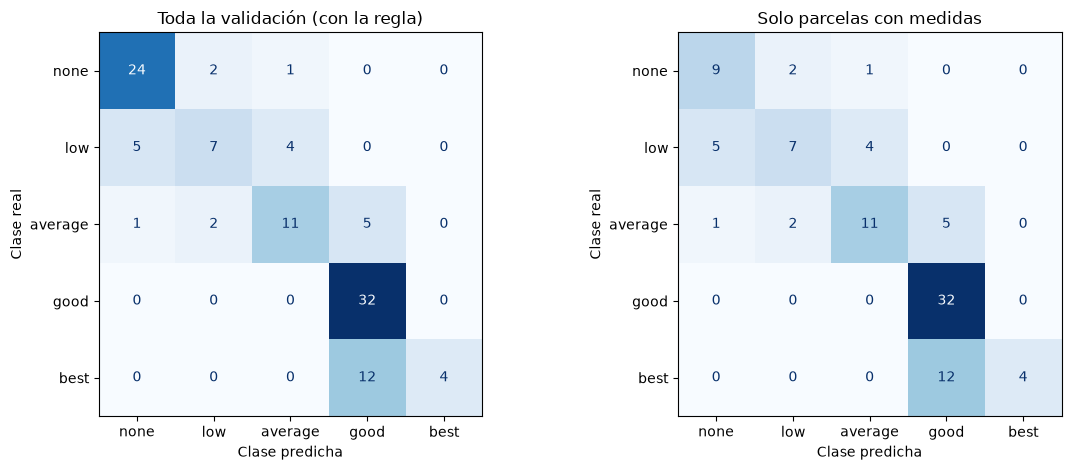

In [7]:
from comun import evaluar_val, mostrar_evaluacion

mejor_modelo = busqueda.best_estimator_
ev = evaluar_val(mejor_modelo, X_train, y_train, X_val, y_val, f1_dummy)
mostrar_evaluacion(ev)

### La regla `none` en validación

**Qué hacemos:** comprobamos que las 15 parcelas sin medidas no pasan por el modelo y se predicen `none` por regla fija (ADR-0001).

In [8]:
sin_medidas_val = ~ev["medidas"]
print(f"Parcelas sin medidas en validación: {sin_medidas_val.sum()}")
print("Predicciones para esas parcelas:", ev["pred"][sin_medidas_val].unique())
print("¿Todas son none?", (ev["pred"][sin_medidas_val] == "none").all())

Parcelas sin medidas en validación: 15
Predicciones para esas parcelas: <StringArray>
['none']
Length: 1, dtype: str
¿Todas son none? True


### Celda de overfitting

**Qué hacemos:** mostramos el gap de F1 macro (train − validación con medidas) y si cumple el máximo de 5 puntos.

In [9]:
from comun import GAP_MAXIMO, nivel_gap

print(
    f"Gap = F1 train ({ev['f1_train']:.3f}) - F1 validación con medidas "
    f"({ev['filas']['solo con medidas']['F1 macro']:.3f}) = {ev['gap']:.1f} puntos"
)
print(f"¿Menor de {GAP_MAXIMO} puntos? {ev['cumple_gap']} → {nivel_gap(ev['gap'])}")

Gap = F1 train (0.631) - F1 validación con medidas (0.601) = 3.0 puntos
¿Menor de 5 puntos? True → ✅ correcto


**Qué vemos:**
- **Gap 3.0 puntos**: F1 de train 0.631 frente a F1 de validación con medidas 0.601. Cumple el criterio de menos de 5 puntos.
- **F1 macro 0.636** en toda la validación (0.601 solo con medidas). El SVM supera claramente al Dummy, que se queda en 0.244 en toda la validación.
- **Clases:** `good` y `none` son las que mejor reconoce. `best` es la peor: casi no la predice (recall 0.25), aunque cuando la dice acierta (precision 1.00). `low` también se queda corta (recall 0.44).
- **Matriz de confusión:** el error más frecuente es `best` → `good` (12 casos), seguido de `average` → `good` (5) y `low` → `none` (5). Casi todos los errores son entre clases vecinas.

## Paso 8: interpretación

### 8.1 Importancia de las variables

**Qué hacemos:** `importancia_permutacion` mide cuánto cae el F1 macro al desordenar cada variable en la validación con medidas.

**Cómo leer el gráfico:** la barra más larga es la variable que más ayuda a acertar. Las barras cercanas a 0 son variables que el modelo puede desordenar sin empeorar.

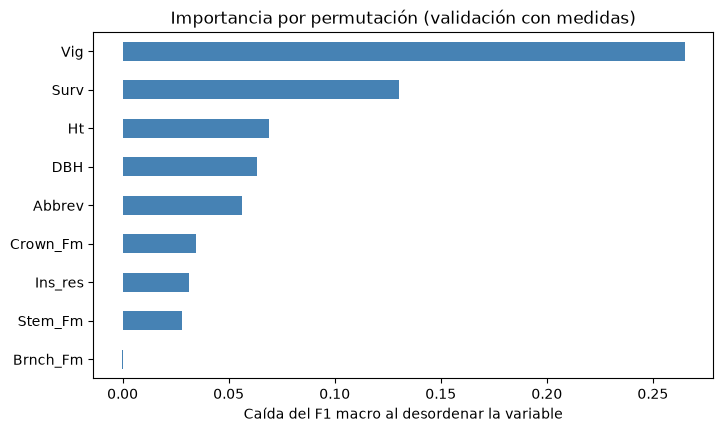

,importancia
Vig,0.265
Surv,0.130
Ht,0.069
DBH,0.064
Abbrev,0.056
Crown_Fm,0.035
Ins_res,0.031
Stem_Fm,0.028
Brnch_Fm,-0.000


In [10]:
from comun import importancia_permutacion

importancia = importancia_permutacion(mejor_modelo, X_val, y_val)
display(importancia.sort_values(ascending=False).to_frame("importancia").round(3))

**Qué vemos:** el **vigor** (`Vig`) es la variable más importante con diferencia (0.265), seguida de la **supervivencia** (`Surv`, 0.130), la **altura** (`Ht`, 0.069), el **diámetro** (`DBH`, 0.064) y el **sitio** (`Abbrev`, 0.056). Cuadra con el EDA: el vigor era la medida más relacionada con la clase. Las formas (`Crown_Fm`, `Ins_res`, `Stem_Fm`, `Brnch_Fm`) aportan poco.

### 8.2 Análisis de errores

**Qué hacemos:** `errores_frecuentes` cuenta los pares real → predicha y marca la distancia entre clases en la escala ordenada. Los errores a 2 o más clases de distancia son los graves.

In [11]:
from comun import errores_frecuentes

errores = errores_frecuentes(ev["y"][ev["medidas"]], ev["pred"][ev["medidas"]])
display(errores)

Errores: 32 de 95. Entre clases vecinas: 30; a 2 o más clases de distancia: 2.


,real,predicha,parcelas,distancia
0,best,good,12,1
1,average,good,5,1
2,low,none,5,1
3,low,average,4,1
4,none,low,2,1
5,average,low,2,1
6,average,none,1,2
7,none,average,1,2


**Qué vemos:**
- **32 errores de 95 parcelas con medidas.** 30 son entre clases vecinas y solo 2 saltan dos clases: el modelo se equivoca sobre todo en los límites.
- **El error dominante es `best` → `good` (12 parcelas).** El SVM prefiere `good` y casi nunca se atreve con `best`; cuando lo hace, acierta. Es el mismo patrón que en el árbol de decisión: `best` es la clase más difícil.
- Después aparecen `average` → `good` (5), `low` → `none` (5) y `low` → `average` (4). `good` tiene recall 1.00: el modelo lo predice mucho, a costa de "comerse" parte de `best` y `average`.
- **Idea para mejorar:** el SVM lineal no separa bien `best` de `good`; un kernel no lineal o más variables de forma podrían ayudar, pero habría que vigilar el sobreajuste.

## Paso 9: guardar el modelo

**Qué hacemos:** `guardar_modelo` guarda el **pipeline completo** (preprocesado + SVM) en `models/04_svm.joblib` y comprueba que, al recargarlo, predice igual.

**Por qué:** la app y `06_conclusiones` cargarán ese fichero. Si solo guardáramos el SVM, habría que repetir a mano la imputación, el escalado y el one-hot, y las predicciones podrían cambiar. La regla `none` no va dentro del pipeline: la aplica quien lo use con `predecir_con_regla`.

In [12]:
import joblib
from sklearn.metrics import f1_score

from comun import guardar_modelo, predecir_con_regla

RUTA_MODELO = guardar_modelo(mejor_modelo, "04_svm", X_val)

modelo_cargado = joblib.load(RUTA_MODELO)
pred_cargado = predecir_con_regla(modelo_cargado, X_val)
print(
    "F1 macro en validación del modelo cargado: "
    f"{f1_score(y_val, pred_cargado, average='macro'):.3f}"
)

Guardado: models/04_svm.joblib (106.9 KB). ¿Al recargarlo predice igual? ✅
F1 macro en validación del modelo cargado: 0.636


### Comprobación en una sesión nueva

Simulamos lo que hará otra persona: leer `data/val.csv` de nuevo desde disco, cargar el `.joblib` y predecir. Si no hay errores y salen 110 filas, el contrato de modelos se cumple.

In [13]:
train_fresco, val_fresco = cargar_datos()
X_val_fresco, y_val_fresco = separar_xy(val_fresco, VARIABLES)
modelo_nuevo = joblib.load("models/04_svm.joblib")
pred_nuevo = predecir_con_regla(modelo_nuevo, X_val_fresco)

print(f"Filas predichas sobre data/val.csv: {len(pred_nuevo)}")
print(f"F1 macro: {f1_score(y_val_fresco, pred_nuevo, average='macro'):.3f}")
assert len(pred_nuevo) == len(y_val_fresco)

Filas predichas sobre data/val.csv: 110
F1 macro: 0.636


## Conclusión

**Qué hacemos:** llamamos a `conclusion_modelo` de `comun.py`, que comprueba los requisitos R1–R6 y guarda las cifras en `resultados/04_svm.json` para que `06_conclusiones` pueda comparar los modelos. Después añadimos los requisitos que se comprueban leyendo el notebook (R7–R11).

In [14]:
from comun import conclusion_modelo, f1_por_fold

cv_elegido = f1_por_fold(mejor_modelo, X_train, y_train)
conclusion_modelo("04_svm", cv_elegido, ev, f1_dummy, busqueda.best_params_)

pd.DataFrame([
    ("R7", "Accuracy, P/R/F1 por clase y matriz de confusión", "Enunciado", "Paso 7", "✅"),
    ("R8", "Feature importance", "Enunciado", "Paso 8.1", "✅"),
    ("R9", "Análisis de errores", "Enunciado", "Paso 8.2", "✅"),
    ("R10", "Preprocesado dentro del Pipeline", "Guía, paso 3", "Paso 3", "✅"),
    ("R11", "No usar el conjunto de prueba", "Acuerdos", "No se lee", "✅"),
], columns=["id", "requisito", "fuente", "dónde", "cumple"]).set_index("id")

,StratifiedKFold,por sitio (StratifiedGroupKFold)
fold,,
1,0.635,0.620
2,0.681,0.464
3,0.634,0.375
4,0.482,0.651
5,0.477,0.428


StratifiedKFold: F1 macro = 0.582 ± 0.085 | gap 4.5 puntos ✅ correcto
Por sitio:       F1 macro = 0.507 ± 0.108 | gap 11.6 puntos


,requisito,fuente,resultado,cumple
id,,,,
R1,Multiclase (≥ 3 clases),Enunciado,5 clases,✅
R2,Overfitting < 5 puntos (train - validación con...,Enunciado,3.0 puntos,✅
R3,Supera claramente al Dummy (validación con med...,"Guía, paso 5",+50 puntos,✅
R4,Sin medidas → none por regla; métricas con y sin,ADR-0001,15 parcelas,✅
R5,StratifiedKFold + comprobación por sitio,ADR-0002,0.582 / 0.507,✅
R6,Pipeline guardado,Acuerdos,models/04_svm.joblib,✅


,validación cruzada,validación con regla,validación solo con medidas
F1 macro,0.582,0.636,0.601
gap (puntos),4.533,NaN,3.024
supera Dummy (puntos),48.483,39.222,49.999


Resultados guardados en resultados/04_svm.json


,requisito,fuente,dónde,cumple
id,,,,
R7,"Accuracy, P/R/F1 por clase y matriz de confusión",Enunciado,Paso 7,✅
R8,Feature importance,Enunciado,Paso 8.1,✅
R9,Análisis de errores,Enunciado,Paso 8.2,✅
R10,Preprocesado dentro del Pipeline,"Guía, paso 3",Paso 3,✅
R11,No usar el conjunto de prueba,Acuerdos,No se lee,✅


### Resumen

| | Validación cruzada | `val.csv` con regla | `val.csv` solo con medidas |
|---|---|---|---|
| F1 macro | 0.582 | 0.636 | 0.601 |
| Gap | 4.5 ✅ | — | 3.0 ✅ |
| Supera al Dummy | +48 puntos | +39 puntos | +50 puntos |

- **Modelo:** SVM lineal con `C = 0.045`, pipeline que imputa la mediana, estandariza las numéricas y hace one-hot del sitio. Guardado en `models/04_svm.joblib`.
- **Lo que hace bien:** controla el sobreajuste, supera claramente al Dummy y reconoce bien `good` y `none`.
- **Lo que hace mal:** es demasiado conservador con `best` (recall 0.25) y lo confunde con `good`; también le cuesta `low`.
- **Comprobación por sitio:** el F1 medio con `StratifiedGroupKFold` baja a 0.507 ± 0.108, coherente con el ADR-0002: el sitio ayuda a predecir y las métricas comunes están algo infladas.
- **Límites:** el SVM lineal no separa bien las clases contiguas altas; el test se evaluará una sola vez en `06_conclusiones`.